# 03. Tranh chấp cung và biến ẩn: thí nghiệm và dữ liệu quan sát lệch bao nhiêu

Trên thị trường gọi xe, voucher cho rider này làm rider khác chờ lâu hơn, vì hai người tranh nhau cùng một đội xe. Giả định SUTVA (kết cục của một đơn vị không phụ thuộc phân nhóm của đơn vị khác) vì vậy vỡ. Simulator cho ta **đáp án đúng** để đo xem mỗi cách ước lượng lệch bao nhiêu:

1. Hiệu ứng toàn hệ thật (GTE): bật voucher cho tất cả so với tắt cho tất cả, không ngân sách.
2. Bốn thiết kế thí nghiệm ước lượng GTE lệch bao nhiêu: A/B theo rider, switchback cụm 1 ô, 7 ô, toàn hệ.
3. Carryover giữa các block của switchback (burn-in).
4. Dữ liệu quan sát từ chính sách cũ: chệch do biến ẩn `u_latent`, theo mức chính sách cũ nhắm vào biến ẩn.

Phép tính trong `analysis/interference.py` (`tests/test_policy_eval.py`). Notebook 05 bàn tiếp vì sao DR-learner không gỡ được phần chệch do `u_latent`.

**Dữ liệu cần** (lệnh sinh lại ở README, mục *Tái lập kết quả*; thế giới W0 = quy mô Hà Nội, tiền VND):

| Thư mục | Nội dung |
|---|---|
| `runs/s8/w0/gte` | all_on và all_off không ngân sách, 10 seed × 1 ngày, ghép cặp theo seed |
| `runs/s8/w0/gte_bigfleet` | như trên với đội xe rất lớn (6.000 xe): mức tăng cầu khi không thiếu xe |
| `runs/s8/w0/rider_ab_28d`, `switchback_c1_28d`, `switchback_c7_28d`, `switchback_call_28d` | bốn thiết kế thí nghiệm, 28 ngày, cùng 4.195.499 session |
| `runs/s8/w0/legacy_28d`, `legacy_gu_{0,0p5,2}_28d` | luật cũ với 4 mức nhắm theo `u_latent` |
| `runs/s9/w0/results` | thác nước ba nguồn sai số và tách burn-in (`python -m analysis.interference waterfall` / `burnin`) |
| `runs/s10/w0/confounding/results` | bảng gây nhiễu theo `target_g_u` (`python -m analysis.interference confounding`) |


In [1]:
from analysis.notebook import require_runs, setup
from analysis.plots import save_figure

plt = setup()   # repository root, shared plot style, wide pandas display
DESIGNS = ["rider_ab_28d", "switchback_c1_28d", "switchback_c7_28d", "switchback_call_28d"]
LEGACY = ["runs/s8/w0/legacy_gu_0_28d", "runs/s8/w0/legacy_gu_0p5_28d", "runs/s8/w0/legacy_28d", "runs/s8/w0/legacy_gu_2_28d"]
gte_dir, gte_big_dir, s9_dir, conf_dir, *rest = require_runs(
    "runs/s8/w0/gte", "runs/s8/w0/gte_bigfleet", "runs/s9/w0/results", "runs/s10/w0/confounding/results",
    *[f"runs/s8/w0/{d}" for d in DESIGNS], *LEGACY)
design_dirs, legacy_dirs = rest[:len(DESIGNS)], rest[len(DESIGNS):]


In [2]:
import pandas as pd
from IPython.display import display

from analysis import figures
import json

from analysis.interference import burnin_markdown, design_table, gte_truth, waterfall_markdown

## 1. Hiệu ứng toàn hệ thật (GTE)

GTE = N(all_on) − N(all_off), cả hai không ngân sách, ghép cặp theo seed (CRN). Đây là đáp án mà mọi thiết kế thí nghiệm cố gắng ước lượng. Với kết cục `requested` (số request), GTE đo phần voucher kéo thêm lượt đặt.

In [3]:
truth = pd.DataFrame({outcome: gte_truth(gte_dir, outcome=outcome) for outcome in ("completed", "requested")}).T
truth.round(1)

,GTE,GTE_se,n_seeds,N_off,N_on
completed,3864.7,40.9,10.0,19371.0,23235.7
requested,7181.1,20.8,10.0,20704.4,27885.5


## 2. Mỗi thiết kế thí nghiệm ước lượng GTE lệch bao nhiêu

Mỗi bộ dữ liệu ngẫu nhiên hóa cho ra con số mà một nhóm phân tích sẽ báo cáo: hiệu tỷ lệ kết cục mỗi session (có voucher trừ không) nhân số session mỗi ngày, tức "nếu bật cho mọi session". Khoảng tin cậy bootstrap theo đơn vị ngẫu nhiên hóa: rider với A/B theo rider, (cụm, block) với switchback. Session trong phút burn-in đầu block của switchback bị bỏ khỏi phép hiệu (Hu & Wager 2022).

In [4]:
designs = design_table(design_dirs, gte_dir, outcome="completed")
display(designs[["design", "n_units", "per_day", "ci_lo", "ci_hi", "GTE", "bias", "bias_pct"]].round(1))

,design,n_units,per_day,ci_lo,ci_hi,GTE,bias,bias_pct
0,rider_ab,119648,9216.9,8962.2,9486.0,3864.7,5352.2,138.5
1,cluster_switchback cụm 1,40990,7261.0,7092.5,7433.2,3864.7,3396.3,87.9
2,cluster_switchback cụm 7,4704,6375.4,5972.7,6764.5,3864.7,2510.7,65.0
3,cluster_switchback cụm all,672,3985.3,2981.3,5131.2,3864.7,120.6,3.1


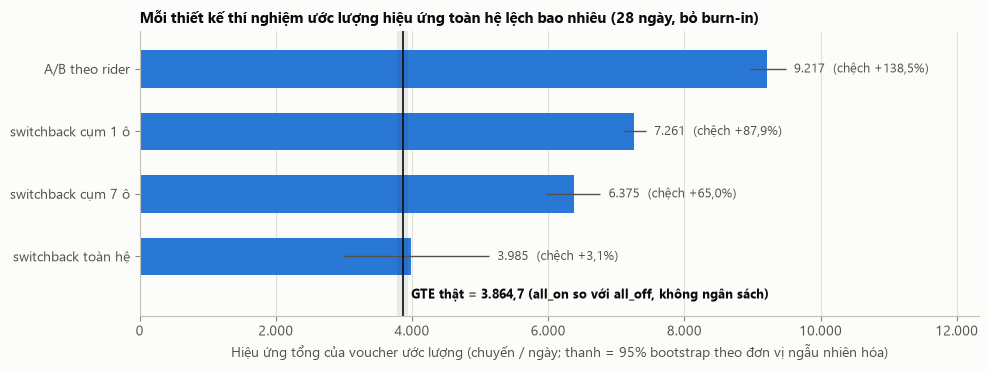

In [5]:
fig = figures.design_bias_figure(designs)
save_figure(fig, "03_chech_thiet_ke")
plt.show()

In [6]:
designs_req = design_table(design_dirs, gte_dir, outcome="requested")
designs_req[["design", "per_day", "ci_lo", "ci_hi", "GTE", "bias", "bias_pct"]].round(1)

,design,per_day,ci_lo,ci_hi,GTE,bias,bias_pct
0,rider_ab,10386.0,10104.9,10700.6,7181.1,3204.9,44.6
1,cluster_switchback cụm 1,9044.1,8893.4,9202.8,7181.1,1863.0,25.9
2,cluster_switchback cụm 7,8525.9,8247.2,8799.1,7181.1,1344.8,18.7
3,cluster_switchback cụm all,7254.4,6614.7,7957.5,7181.1,73.3,1.0


**Đọc kết quả** (W0, quy mô Hà Nội; so với thành phố cũ (nhỏ hơn) chệch tăng mạnh vì đội xe bị ràng buộc hơn).

- **A/B theo rider phóng đại 2,4 lần** (+9.217 so với GTE +3.865 chuyến/ngày, +138%; trên thành phố cũ chỉ +36%). Rider được voucher và rider không được voucher ở cùng ô, cùng giờ, tranh cùng một đội xe: nhóm có voucher lấy xe của nhóm không có, nên hiệu "có − không" đếm cả chuyến **chuyển** từ nhóm kia sang, không chỉ chuyến **thêm**.
- **Switchback theo cụm giảm dần chệch khi cụm lớn dần** (cụm 1 ô +88%, cụm 7 ô +65%) nhưng vẫn rất xa sự thật: xe chảy qua biên cụm.
- **Switchback toàn thành phố gần đúng** (+3,1%, CI [−23%; +33%] chứa 0): không còn tranh chấp giữa hai nhánh, chỉ còn burn-in và ảnh hưởng kéo dài (mục 3).
- Trên kết cục **request** chệch nhỏ hơn (+45% / +26% / +19% / +1%): tranh chấp xe tác động lên hoàn thành nhiều hơn lên đặt xe.
- Trên W1 (có biến động) các con số gần như trùng (A/B +147%, cụm 1 +96%, cụm 7 +73%, toàn thành phố +6%), nhưng CI của GTE rộng gấp 7 lần (SE 295 so với 41).


## 3. Burn-in và ảnh hưởng kéo dài của switchback toàn thành phố

Trong switchback, trạng thái xe đầu khối là hệ quả của khối trước (xe đang chở khách của khối trước, vị trí xe). Ước lượng trên mọi session trừ ước lượng bỏ 15 phút đầu mỗi khối (`in_burnin`) là **burn-in bias**; ước lượng bỏ burn-in trừ GTE là **ảnh hưởng kéo dài**. Bảng đọc từ `runs/s9/w0/results/burnin_completed.parquet`.


In [7]:
burnin = pd.read_parquet(s9_dir / "burnin_completed.parquet")
print(burnin_markdown(burnin))
burnin.round(1)


| | chuyến/ngày | 95% CI |
|---|---|---|
| switchback toàn thành phố, mọi session | +4.579,2 | [+3.611,0; +5.676,1] |
| switchback, bỏ burn-in | +3.985,3 | [+2.981,3; +5.131,2] |
| GTE | +3.864,7 | [+3.785,3; +3.942,0] |
| burn-in bias (mọi session − bỏ burn-in) | +593,9 | [+483,4; +699,8] |
| carry-over (bỏ burn-in − GTE) | +120,6 | [−896,2; +1.266,4] |

Session dùng: 4,193,232 (mọi) / 3,144,924 (bỏ burn-in).


,name,value,ci_lo,ci_hi
0,"switchback toàn thành phố, mọi session",4579.2,3611.0,5676.1
1,"switchback, bỏ burn-in",3985.3,2981.3,5131.2
2,GTE,3864.7,3785.3,3942.0
3,burn-in bias (mọi session − bỏ burn-in),593.9,483.4,699.8
4,carry-over (bỏ burn-in − GTE),120.6,-896.2,1266.4


Switchback toàn thành phố ước cao hơn GTE 18% (+4.579 so với +3.865). Phần có ý nghĩa thống kê là **burn-in +594 [483; 700]** chuyến/ngày; phần **kéo dài +121 [−896; +1.266]** có khoảng tin cậy chứa 0. Bỏ 15 phút đầu khối là đủ để thiết kế này gần đúng; W1 cho cùng kết luận (+590 và +228, CI chứa 0).


## 3b. Thác nước ba nguồn sai số trên cùng một thang

Bốn mức, đều là chuyến/ngày nếu mọi session được phát so với không: **so thô** trên dữ liệu luật cũ (phát − không phát, ngoài lát explore); **mức mỗi khách** (A/B theo rider, không nhiễu ẩn, cùng chợ); **GTE**; **GTE với đội xe rất lớn**. Ba phần: gây nhiễu = so thô − mức mỗi khách; tranh chấp xe = mức mỗi khách − GTE; công suất = GTE − GTE đội xe rất lớn. Gây nhiễu + tranh chấp phải bằng so thô − GTE. Bảng đọc từ `runs/s9/w0/results/waterfall_completed.parquet`.


| | Mức / phần | chuyến/ngày | 95% CI |
|---|---|---|---|
| level | raw (legacy, so thô) | +13.453,3 | [+13.263,9; +13.623,7] |
| level | per-rider (rider_ab) | +9.216,9 | [+8.962,2; +9.486,0] |
| level | GTE (đội xe chuẩn) | +3.864,7 | [+3.785,3; +3.942,0] |
| level | GTE (đội xe rất lớn) | +12.184,9 | [+12.144,0; +12.225,4] |
| step | confounding (so thô − mốc không gây nhiễu) | +4.236,5 | [+3.884,8; +4.557,1] |
| step | competition (tranh chấp xe: mức mỗi khách − GTE) | +5.352,2 | [+5.086,8; +5.642,3] |
| step | capacity (công suất: GTE − GTE đội xe rất lớn) | −8.320,2 | [−8.405,1; −8.229,2] |

Tổng ba phần +1.268,4 = so thô − GTE đội xe rất lớn +1.268,4 (khớp).


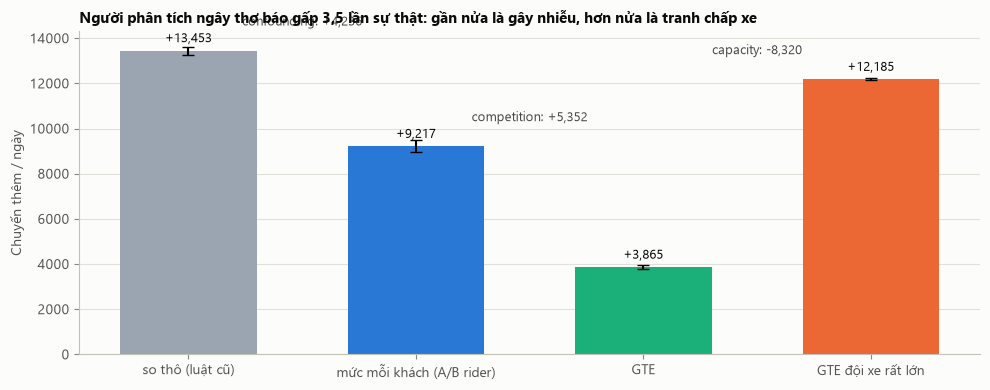

In [8]:
waterfall = pd.read_parquet(s9_dir / "waterfall_completed.parquet")
waterfall.attrs = json.loads((s9_dir / "waterfall_completed_attrs.json").read_text(encoding="utf-8"))
print(waterfall_markdown(waterfall))
levels = waterfall[waterfall["kind"] == "level"].reset_index(drop=True)
steps = waterfall[waterfall["kind"] == "step"].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 4))
x = list(range(len(levels)))
ax.bar(x, levels["value"], color=["#9aa5b1", "#2a78d6", "#1baf7a", "#eb6834"], width=0.6)
for i, r in levels.iterrows():
    ax.errorbar(i, r["value"], yerr=[[r["value"] - r["ci_lo"]], [r["ci_hi"] - r["value"]]], color="black", capsize=4)
    ax.annotate(f"{r['value']:+,.0f}", xy=(i, r["value"]), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=9)
for i, r in steps.iterrows():
    label = r["name"].split(" (")[0]
    top = max(levels.loc[i, "value"], levels.loc[i + 1, "value"])
    ax.annotate(f"{label}: {r['value']:+,.0f}", xy=(i + 0.5, top), xytext=(0, 18), textcoords="offset points",
                ha="center", fontsize=9, color="#444444")
ax.set_xticks(x, ["so thô (luật cũ)", "mức mỗi khách (A/B rider)", "GTE", "GTE đội xe rất lớn"])
ax.set_ylabel("Chuyến thêm / ngày")
ax.set_title("Người phân tích ngây thơ báo gấp 3,5 lần sự thật: gần nửa là gây nhiễu, hơn nửa là tranh chấp xe")
fig.tight_layout()
save_figure(fig, "03_thac_nuoc")
plt.show()


**Đọc kết quả.** So thô +13.453 → mức mỗi khách +9.217 → GTE +3.865: **gây nhiễu +4.237 [3.885; 4.557]** và **tranh chấp xe +5.352 [5.087; 5.642]** cộng đúng bằng so thô − GTE (+9.589). Phần **công suất** là chuyện khác: đội xe chuẩn chỉ giữ được 32% mức tăng cầu (GTE +3.865 so với +12.185 khi không thiếu xe) — đó là giới hạn của chính sự thật, không phải sai số ước lượng. W1: gây nhiễu +4.986, tranh chấp +5.424, công suất giữ 30%.


## 4. Dữ liệu quan sát: chệch do biến ẩn `u_latent`

Chính sách cũ (`legacy`) nhắm voucher theo một quy tắc có dùng `u_latent`, một đặc trưng rider mà dữ liệu quan sát **không** có (giống thực tế: nhân viên vận hành biết điều mà dữ liệu không ghi). `u_latent` cũng làm rider hay đặt xe hơn, nên rider được phát voucher vốn đã hay đi: so sánh "được phát" với "không được phát" phóng đại hiệu ứng. Chính sách cũ có lát explore 5% ngẫu nhiên hóa, cho đáp án không chệch trên cùng dữ liệu.

Bốn bộ legacy 28 ngày chỉ khác `target_g_u` (mức quy tắc cũ dựa vào `u_latent`), cùng tập session (cùng `run_seed`). Hai ước lượng quan sát:

- **so thô**: được phát so với không, mọi session ngoài lát explore; so với toàn bộ lát explore;
- **điều chỉnh theo X**: được phát so với không trong từng tầng (phân khúc × thập phân vị tần suất), chỉ ô đang bật khuyến mãi; so với lát explore của ô đang bật.

Phần chệch còn lại sau điều chỉnh theo X là phần do `u_latent`.

In [9]:
# python -m analysis.interference confounding runs/s8/w0/legacy_gu_0_28d ... --out runs/s10/w0/confounding (6 phút)
confounding = pd.read_parquet(conf_dir / "confounding_by_u_latent.parquet").sort_values("target_g_u").reset_index(drop=True)
confounding[["target_g_u", "share_offered", "naive", "explore_all", "bias_naive", "bias_naive_lo", "bias_naive_hi",
             "adjusted", "explore_on", "bias_adjusted", "bias_adjusted_lo", "bias_adjusted_hi"]].round(4)


,target_g_u,share_offered,naive,explore_all,bias_naive,bias_naive_lo,bias_naive_hi,adjusted,explore_on,bias_adjusted,bias_adjusted_lo,bias_adjusted_hi
0,0.0,0.2090,0.0503,0.0577,-0.0074,-0.0101,-0.0042,0.0617,0.0608,0.0010,-0.0028,0.0047
1,0.5,0.2111,0.0732,0.0586,0.0145,0.0116,0.0176,0.0876,0.0622,0.0254,0.0219,0.0297
2,1.0,0.2113,0.0909,0.0556,0.0352,0.0321,0.0385,0.1065,0.0581,0.0484,0.0445,0.0525
3,2.0,0.2062,0.1126,0.0535,0.0592,0.0558,0.0622,0.1259,0.0562,0.0697,0.0651,0.0743


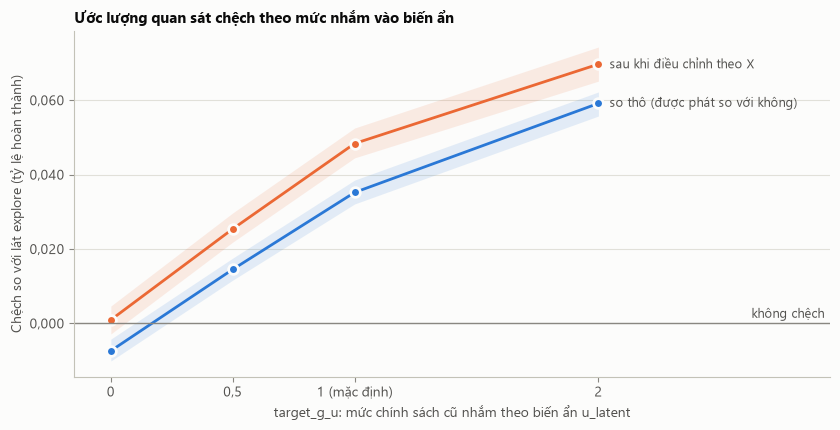

In [10]:
fig = figures.u_latent_figure(confounding)
save_figure(fig, "03_chech_u_latent")
plt.show()

**Đọc kết quả.**

- Khi quy tắc cũ **không** dựa vào biến ẩn (`target_g_u` = 0), điều chỉnh theo X là đủ: chệch còn lại không khác 0.
- Chệch tăng gần tuyến tính theo `target_g_u`. Ở mức mặc định (1), ước lượng quan sát đã điều chỉnh vẫn lớn hơn mốc không gây nhiễu (lát explore) 63% (+0,035 trên mốc +0,056 ở `target_g_u` = 1) (+0,043 trên nền ≈ 0,07); ở mức 2 thì hơn gấp đôi.
- Điều chỉnh theo X **không giảm** chệch so với so thô (đường cam nằm trên đường xanh): các đặc trưng quan sát được không mang thông tin về `u_latent`. Không có biến công cụ hay lát ngẫu nhiên hóa thì không gỡ được phần này; notebook 05 cho thấy DR-learner cũng không gỡ được.

## Tóm tắt (W0, chuyến hoàn thành / ngày)

| Nguồn sai số | Cách đo trong simulator | Độ lớn |
|---|---|---|
| Gây nhiễu (biến ẩn `u_latent`) | so thô trên luật cũ − mức mỗi khách (A/B rider) | +4.237 [3.885; 4.557] |
| Tranh chấp xe (interference) | mức mỗi khách − GTE | +5.352 [5.087; 5.642] |
| Công suất | GTE − GTE đội xe rất lớn | −8.320 (đội xe giữ 32% mức tăng cầu) |
| Burn-in của switchback toàn thành phố | mọi session − bỏ 15 phút đầu khối | +594 [483; 700] |
| Ảnh hưởng kéo dài | bỏ burn-in − GTE | +121 [−896; +1.266] (không khác 0) |

Hai dòng đầu cộng lại đúng bằng so thô − GTE (+9.589): người phân tích chỉ có dữ liệu lịch sử báo gấp 3,5 lần sự thật. Thiết kế duy nhất gần đúng là switchback toàn thành phố bỏ burn-in (+3,1%); A/B theo rider — thiết kế hay dùng nhất — chệch +138% trên quy mô Hà Nội.
